In [ ]:
import os, shutil
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!mkdir -p /root/radiografias/
!unzip "drive/MyDrive/Datos/radiografias.zip" -d "/root/"

Archive:  drive/MyDrive/Datos/radiografias.zip
   creating: /root/radiografias/entrenamiento/
   creating: /root/radiografias/entrenamiento/neumonia/
  inflating: /root/radiografias/entrenamiento/neumonia/BACTERIA-1008087-0001.jpeg  
  inflating: /root/radiografias/entrenamiento/neumonia/BACTERIA-1025587-0001.jpeg  
  inflating: /root/radiografias/entrenamiento/neumonia/BACTERIA-1027194-0001.jpeg  
  inflating: /root/radiografias/entrenamiento/neumonia/BACTERIA-1033441-0001.jpeg  
  inflating: /root/radiografias/entrenamiento/neumonia/BACTERIA-103798-0001.jpeg  
  inflating: /root/radiografias/entrenamiento/neumonia/BACTERIA-103798-0002.jpeg  
  inflating: /root/radiografias/entrenamiento/neumonia/BACTERIA-1039608-0001.jpeg  
  inflating: /root/radiografias/entrenamiento/neumonia/BACTERIA-1040986-0001.jpeg  
  inflating: /root/radiografias/entrenamiento/neumonia/BACTERIA-1041881-0001.jpeg  
  inflating: /root/radiografias/entrenamiento/neumonia/BACTERIA-1041881-0002.jpeg  
  inflating:

In [ ]:
print('total training neumonia images:', len(os.listdir('/root/radiografias/entrenamiento/neumonia')))

total training neumonia images: 1000


In [ ]:
# Preparación de las imagenes en crudo en su representación en tensor

from keras.preprocessing.image import ImageDataGenerator

In [ ]:
train_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

In [ ]:
train_generator = train_datagen.flow_from_directory(
    '/root/radiografias/entrenamiento',
    target_size=(150, 150),
    batch_size=20,
    class_mode='binary')

Found 2000 images belonging to 2 classes.


In [ ]:
validation_generator = test_datagen.flow_from_directory(
    '/root/radiografias/validacion',
    target_size=(150, 150),
    batch_size=20,
    class_mode='binary')

Found 666 images belonging to 2 classes.


In [ ]:

for data_batch, labels_batch in train_generator:
    print('data batch shape:', data_batch.shape)
    print('labels batch shape:', labels_batch.shape)
    break

data batch shape: (20, 150, 150, 3)
labels batch shape: (20,)


In [ ]:
from keras.applications import VGG16
conv_base = VGG16(weights='imagenet', include_top=False, input_shape=(150, 150, 3))

58889256/58889256 [==============================] - 0s 0us/step


In [ ]:
conv_base.summary()

Model: "vgg16"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 150, 150, 3)]     0         
                                                                 
 block1_conv1 (Conv2D)       (None, 150, 150, 64)      1792      
                                                                 
 block1_conv2 (Conv2D)       (None, 150, 150, 64)      36928     
                                                                 
 block1_pool (MaxPooling2D)  (None, 75, 75, 64)        0         
                                                                 
 block2_conv1 (Conv2D)       (None, 75, 75, 128)       73856     
                                                                 
 block2_conv2 (Conv2D)       (None, 75, 75, 128)       147584    
                                                                 
 block2_pool (MaxPooling2D)  (None, 37, 37, 128)       0     

In [ ]:
conv_base.trainable = False

In [ ]:
from keras import models
from keras import layers

model = models.Sequential()
model.add(conv_base)
model.add(layers.Flatten())
model.add(layers.Dense(256, activation='relu'))
model.add(layers.Dense(1, activation='sigmoid'))

In [ ]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 vgg16 (Functional)          (None, 4, 4, 512)         14714688  
                                                                 
 flatten (Flatten)           (None, 8192)              0         
                                                                 
 dense (Dense)               (None, 256)               2097408   
                                                                 
 dense_1 (Dense)             (None, 1)                 257       
                                                                 
Total params: 16812353 (64.13 MB)
Trainable params: 2097665 (8.00 MB)
Non-trainable params: 14714688 (56.13 MB)
_________________________________________________________________


In [ ]:
from tensorflow.keras import optimizers

model.compile(loss='binary_crossentropy', optimizer=optimizers.RMSprop(learning_rate=1e-4), metrics=['acc'])

In [ ]:
history = model.fit_generator(train_generator, steps_per_epoch=100, epochs=30, validation_data=validation_generator, validation_steps=33)

<ipython-input-16-500bbee5f71c>:1: UserWarning: `Model.fit_generator` is deprecated and will be removed in a future version. Please use `Model.fit`, which supports generators.
  history = model.fit_generator(train_generator, steps_per_epoch=100, epochs=30, validation_data=validation_generator, validation_steps=33)


Epoch 1/30
100/100 [==============================] - 41s 348ms/step - loss: 0.2911 - acc: 0.8835 - val_loss: 0.1955 - val_acc: 0.9318
Epoch 2/30
100/100 [==============================] - 33s 327ms/step - loss: 0.1520 - acc: 0.9430 - val_loss: 0.1853 - val_acc: 0.9258
Epoch 3/30
100/100 [==============================] - 35s 354ms/step - loss: 0.1327 - acc: 0.9510 - val_loss: 0.1470 - val_acc: 0.9424
Epoch 4/30
100/100 [==============================] - 35s 346ms/step - loss: 0.1103 - acc: 0.9595 - val_loss: 0.1437 - val_acc: 0.9348
Epoch 5/30
100/100 [==============================] - 32s 317ms/step - loss: 0.1038 - acc: 0.9600 - val_loss: 0.1665 - val_acc: 0.9288
Epoch 6/30
100/100 [==============================] - 32s 315ms/step - loss: 0.0846 - acc: 0.9740 - val_loss: 0.1416 - val_acc: 0.9485
Epoch 7/30
100/100 [==============================] - 33s 325ms/step - loss: 0.0831 - acc: 0.9715 - val_loss: 0.1380 - val_acc: 0.9515
Epoch 8/30
100/100 [==============================] - 3

In [ ]:
history_dict = history.history

In [ ]:
history_dict.keys()

dict_keys(['loss', 'acc', 'val_loss', 'val_acc'])

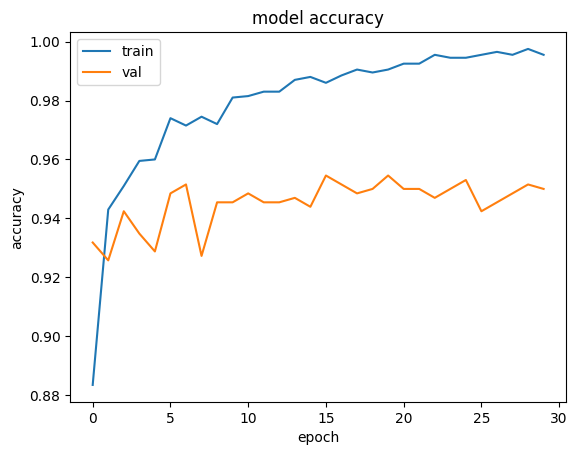

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['acc'])
plt.plot(history.history['val_acc'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

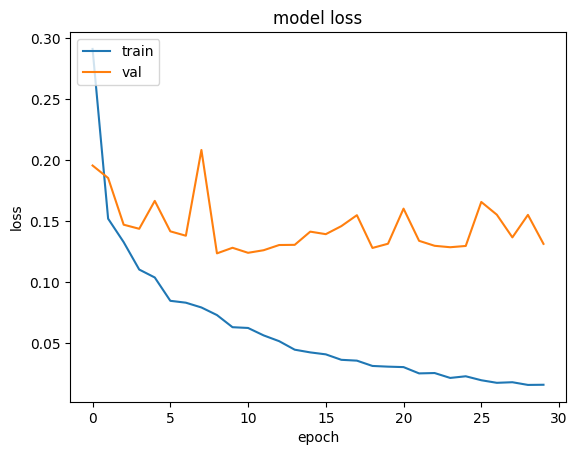

In [ ]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

In [ ]:
test_generator = test_datagen.flow_from_directory(
    '/root/radiografias/test',
    target_size=(150, 150),
    batch_size=20,
    class_mode='binary')

Found 500 images belonging to 2 classes.


In [ ]:
# estimar la preción al predecir todo el dataset
scores = model.evaluate(test_generator)
print("%s: %.2f%%" % (model.metrics_names[1], scores[1]*100))

25/25 [==============================] - 6s 222ms/step - loss: 0.0963 - acc: 0.9700
acc: 97.00%
